# Экзопланеты NASA: как способы обнаружения формируют картину открытий

**Цель.** Исследовать размеры, массы и орбиты подтверждённых экзопланет, а также проверить, связаны ли наблюдаемые различия с методом обнаружения.

Экзопланета — планета за пределами Солнечной системы. Источник данных — [NASA Exoplanet Archive](https://exoplanetarchive.ipac.caltech.edu/), таблица [Planetary Systems Composite Parameters (PSCompPars)](https://exoplanetarchive.ipac.caltech.edu/docs/API_PS_columns.html). Она содержит одну строку на подтверждённую планету и объединяет наиболее заполненные оценки параметров из разных публикаций. Используем локальный снимок `exoplanets.csv`, загруженный **18 октября 2026 года**; результаты относятся именно к этому снимку.

### Исследовательские гипотезы

1. **H1 (Размер планет).** Транзитный метод имеет наблюдательное смещение в сторону планет с меньшим радиусом по сравнению с методом лучевых скоростей (`Radial Velocity`).
2. **H2 (Орбитальный период).** Транзитный метод фиксирует более короткие орбитальные периоды. Мы предполагаем, что это связано с геометрией наблюдений, а не с реальным различием в распределении планет во Вселенной.
3. **H3 (Связь с родительской звездой).** Существует корреляция между радиусом планеты и эффективной температурой её звезды.

| Признак в ноутбуке | Поле NASA | Смысл и единицы |
|---|---|---|
| `mass_earth` | `pl_bmasse` | Лучшая доступная оценка массы или $M\sin i$, в массах Земли |
| `radius_earth` | `pl_rade` | Радиус планеты, в радиусах Земли |
| `orbital_period_days` | `pl_orbper` | Орбитальный период, в сутках |
| `discovery_method` | `discoverymethod` | Метод первого обнаружения |
| `discovery_year` | `disc_year` | Год открытия |
| `star_temperature_k` | `st_teff` | Эффективная температура звезды, K |

**Важно:** Каждый метод обнаружения обладает своими физическими ограничениями. Транзитный метод лучше фиксирует близкие к звезде планеты, а метод лучевых скоростей — массивные. Поэтому частоты в каталоге отражают не истинную популяцию планет во Вселенной, а совокупность возможностей наших телескопов (эффект наблюдательной селекции).

## 1. Загрузка и первичная проверка

Путь к файлу задан в одном месте. Для своего CSV измените `DATA_PATH`; если это другая выгрузка NASA, понадобятся перечисленные выше исходные поля.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.family"] = "DejaVu Sans"

DATA_PATH = Path("exoplanets.csv")  # Например: Path(r"C:\data\exoplanets.csv")
df = pd.read_csv(DATA_PATH)
raw = df.copy()
print(f"Размер исходных данных: {df.shape[0]:,} строк × {df.shape[1]} столбцов")
display(df.head())

Размер исходных данных: 6,451 строк × 8 столбцов


,pl_name,pl_bmasse,pl_rade,pl_orbper,discoverymethod,disc_year,st_teff,disc_facility
0,55 Cnc b,263.9785,13.900,14.651552,Radial Velocity,1996,5198.0,Lick Observatory
1,55 Cnc c,54.4738,8.510,44.393600,Radial Velocity,2004,5198.0,McDonald Observatory
2,55 Cnc d,1232.4930,13.000,4799.000000,Radial Velocity,2002,5198.0,Lick Observatory
3,55 Cnc e,7.9900,1.875,0.736547,Radial Velocity,2004,5172.0,McDonald Observatory
4,55 Cnc f,44.8120,7.590,260.580000,Radial Velocity,2007,5198.0,Multiple Observatories


In [2]:
df.info()
display(df.describe())
display(df.isna().sum().rename("Пропуски").to_frame())

<class 'pandas.DataFrame'>
RangeIndex: 6451 entries, 0 to 6450
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pl_name          6451 non-null   str    
 1   pl_bmasse        6421 non-null   float64
 2   pl_rade          6401 non-null   float64
 3   pl_orbper        6097 non-null   float64
 4   discoverymethod  6451 non-null   str    
 5   disc_year        6451 non-null   int64  
 6   st_teff          6144 non-null   float64
 7   disc_facility    6451 non-null   str    
dtypes: float64(4), int64(1), str(3)
memory usage: 403.3 KB


,pl_bmasse,pl_rade,pl_orbper,disc_year,st_teff
count,6421.000000,6401.000000,6.097000e+03,6451.000000,6144.000000
mean,402.686345,5.844661,7.021580e+04,2017.403038,5389.434811
std,1141.945014,5.400441,5.150759e+06,5.202505,1719.078393
min,0.020000,0.309800,9.070629e-02,1992.000000,415.000000
25%,4.350000,1.850000,4.288178e+00,2014.000000,4893.750000
50%,9.320000,2.860000,1.064130e+01,2016.000000,5544.000000
75%,189.101000,11.900000,3.799327e+01,2021.000000,5900.000000
max,12651.500000,87.205870,4.020000e+08,2026.000000,57000.000000


,Пропуски
pl_name,0
pl_bmasse,30
pl_rade,50
pl_orbper,354
discoverymethod,0
disc_year,0
st_teff,307
disc_facility,0


### Логика предобработки данных

**Критические пропуски:** Записи без названия, года или метода открытия удаляем, так как они бесполезны для анализа истории открытий.

**Физические пропуски:** Если неизвестна масса или радиус, мы не удаляем планету из общего датасета. Она всё еще важна для анализа дат открытий. Однако при построении графиков (например, «масса-радиус») мы будем использовать только подвыборки с полными данными. Заполнять пропуски средними значениями в астрофизике нельзя — это исказит распределение.

**Кривые данные:** Масса, радиус и период не могут быть отрицательными или нулевыми (особенно для логарифмических шкал), поэтому такие значения переводим в `NaN`.

In [3]:
rename = {
    "pl_name": "planet_name",
    "pl_bmasse": "mass_earth",
    "pl_rade": "radius_earth",
    "pl_orbper": "orbital_period_days",
    "discoverymethod": "discovery_method",
    "disc_year": "discovery_year",
    "st_teff": "star_temperature_k",
    "disc_facility": "discovery_facility",
}
missing_columns = set(rename) - set(raw.columns)
if missing_columns:
    raise ValueError(f"В CSV отсутствуют поля NASA: {sorted(missing_columns)}")

df = raw.rename(columns=rename).copy()
for column in ("mass_earth", "radius_earth", "orbital_period_days", "star_temperature_k", "discovery_year"):
    df[column] = pd.to_numeric(df[column], errors="coerce")
for column in ("mass_earth", "radius_earth", "orbital_period_days"):
    df.loc[df[column] <= 0, column] = np.nan

before = len(df)
df = df.drop_duplicates().drop_duplicates(subset="planet_name")
df = df.dropna(subset=["planet_name", "discovery_method", "discovery_year"])
df["discovery_year"] = df["discovery_year"].astype(int)
print(f"Удалено записей (дубликаты и пропуски ключевых полей): {before - len(df)}")
print(f"Осталось планет: {len(df):,}")
display(df.isna().sum().rename("Пропуски после очистки").to_frame())

df_radius = df.dropna(subset=["radius_earth"]).copy()
df_physical = df.dropna(subset=["mass_earth", "radius_earth"]).copy()
df_period = df.dropna(subset=["orbital_period_days"]).copy()
print(f"Выборки: радиус — {len(df_radius):,}; масса + радиус — {len(df_physical):,}; период — {len(df_period):,}")

Удалено записей (дубликаты и пропуски ключевых полей): 0
Осталось планет: 6,451


,Пропуски после очистки
planet_name,0
mass_earth,30
radius_earth,50
orbital_period_days,354
discovery_method,0
discovery_year,0
star_temperature_k,307
discovery_facility,0


Выборки: радиус — 6,401; масса + радиус — 6,378; период — 6,097


### Новый признак: относительная плотность

Для планет с известными массой и радиусом вычисляем $\rho / \rho_{\oplus} = (M/M_{\oplus}) / (R/R_{\oplus})^3$. Это помогает сравнить планеты с одинаковыми размерами, но разной массой. Поскольку `pl_bmasse` иногда означает $M\sin i$, а составная таблица может объединять оценки из разных работ, это **приближение**, а не надёжно измеренная физическая плотность. Дополнительно переводим период в земные годы для удобства интерпретации.

In [4]:
df["orbital_period_years"] = df["orbital_period_days"] / 365.25
df["relative_density"] = df["mass_earth"] / df["radius_earth"] ** 3
df_physical = df.dropna(subset=["mass_earth", "radius_earth"]).copy()
display(df_physical[["planet_name", "mass_earth", "radius_earth", "relative_density"]].head())

,planet_name,mass_earth,radius_earth,relative_density
0,55 Cnc b,263.9785,13.900,0.098293
1,55 Cnc c,54.4738,8.510,0.088389
2,55 Cnc d,1232.4930,13.000,0.560989
3,55 Cnc e,7.9900,1.875,1.212113
4,55 Cnc f,44.8120,7.590,0.102487


## 2. Одномерный анализ: размеры и история открытий

Сначала посмотрим на распределения без разбиения по методам. Логарифмическая ось радиуса позволяет видеть одновременно маленькие планеты и газовые гиганты. Год открытия считаем по **всем** планетам после базовой очистки, включая те, у которых масса или радиус неизвестны.

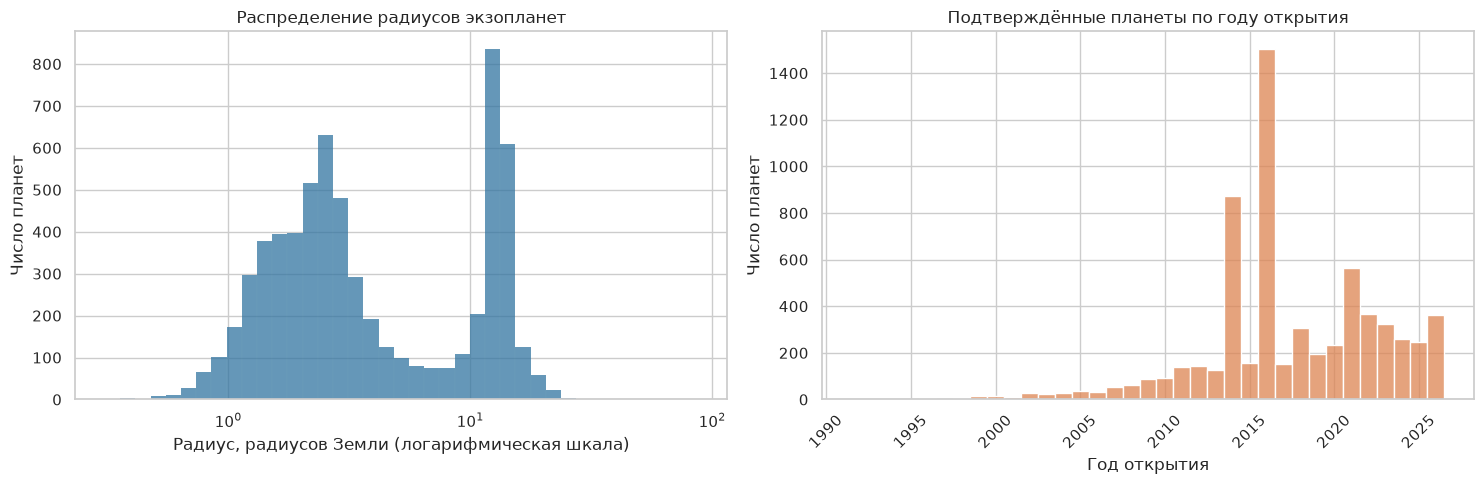

Число планет по диапазонам радиуса (в радиусах Земли):


,Планет
radius_earth,
≤ 2,1819
2–4,2104
4–10,622
> 10,1856


Годы с наибольшим числом открытий:


,Планет
Год,
2016,1504
2014,872
2021,564
2022,367
2026,361


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
radius_bins = np.geomspace(df_radius["radius_earth"].min(), df_radius["radius_earth"].max(), 40)
sns.histplot(data=df_radius, x="radius_earth", bins=radius_bins, ax=axes[0], color="#3274a1")
axes[0].set_xscale("log")
axes[0].set_title("Распределение радиусов экзопланет")
axes[0].set_xlabel("Радиус, радиусов Земли (логарифмическая шкала)")
axes[0].set_ylabel("Число планет")

year_bins = np.arange(df["discovery_year"].min() - 0.5, df["discovery_year"].max() + 1.5, 1)
sns.histplot(data=df, x="discovery_year", bins=year_bins, ax=axes[1], color="#dd8452")
axes[1].set_title("Подтверждённые планеты по году открытия")
axes[1].set_xlabel("Год открытия")
axes[1].set_ylabel("Число планет")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

size_groups = pd.cut(df_radius["radius_earth"], [0, 2, 4, 10, np.inf], labels=["≤ 2", "2–4", "4–10", "> 10"])
print("Число планет по диапазонам радиуса (в радиусах Земли):")
display(size_groups.value_counts().sort_index().to_frame("Планет"))
print("Годы с наибольшим числом открытий:")
display(df["discovery_year"].value_counts().head(5).rename_axis("Год").to_frame("Планет"))

**Интерпретация:** На гистограмме радиусов отчетливо виден пик в диапазоне 2–4 радиусов Земли. В астрофизике такие планеты называют «суперземлями» и «мини-нептунами». Также заметна большая группа газовых гигантов (> 10 радиусов Земли).

График по годам показывает, что количество открытий резко возросло в 2010-х годах. Пик в 2016 году (более 1500 планет) — это прямое следствие массовых публикаций данных с телескопа «Кеплер». Это отражает этап обработки накопленных данных, а не резкое увеличение реальной популяции планет во Вселенной.

## 3. Радиус и масса

Ожидаем общую положительную связь, но не прямую пропорциональность: масса зависит от состава и плотности. Здесь остаются только планеты с обеими положительными оценками; логарифмические оси раскрывают диапазон в несколько порядков.

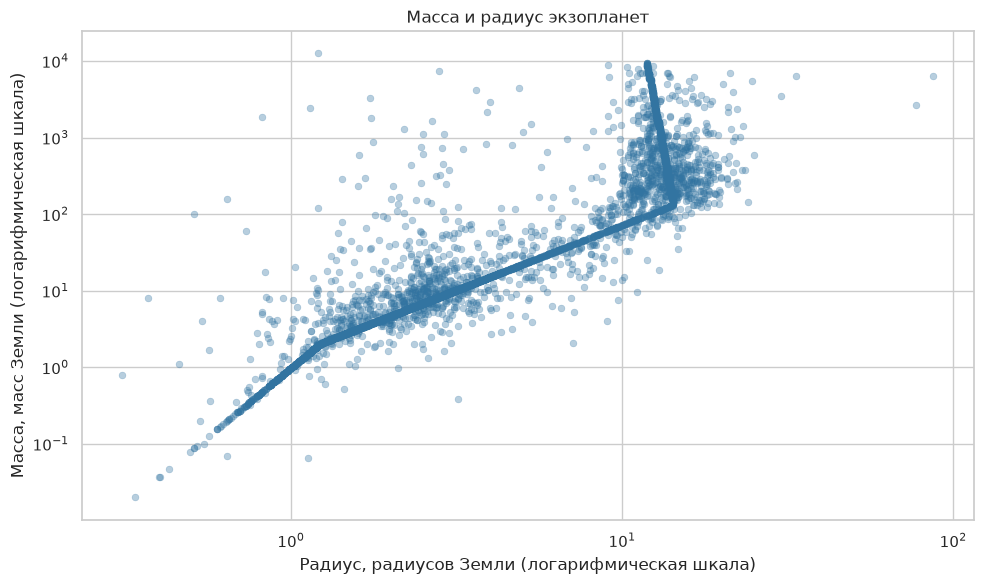

In [6]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_physical, x="radius_earth", y="mass_earth", alpha=0.35, s=24, color="#3274a1", edgecolor=None)
plt.xscale("log")
plt.yscale("log")
plt.title("Масса и радиус экзопланет")
plt.xlabel("Радиус, радиусов Земли (логарифмическая шкала)")
plt.ylabel("Масса, масс Земли (логарифмическая шкала)")
plt.tight_layout()
plt.show()

**Интерпретация:** Видна общая положительная связь: чем больше радиус, тем выше масса. Однако при одинаковом радиусе масса может различаться в десятки раз. Это связано с колоссальной разницей в плотности: газовые гиганты (как Юпитер) при большом радиусе имеют низкую плотность, тогда как скалистые планеты (как Земля) плотнее. Следовательно, только радиус или только масса не дают представления о составе планеты.

## 4. Орбитальный период, год открытия и метод

Цвет обозначает способ первого обнаружения. Для читаемости редкие методы объединены в «Другие» **только на графике**; в таблице группировки ниже сохраняются исходные названия. Логарифмическая ось периода нужна из-за крайне длинного правого хвоста.

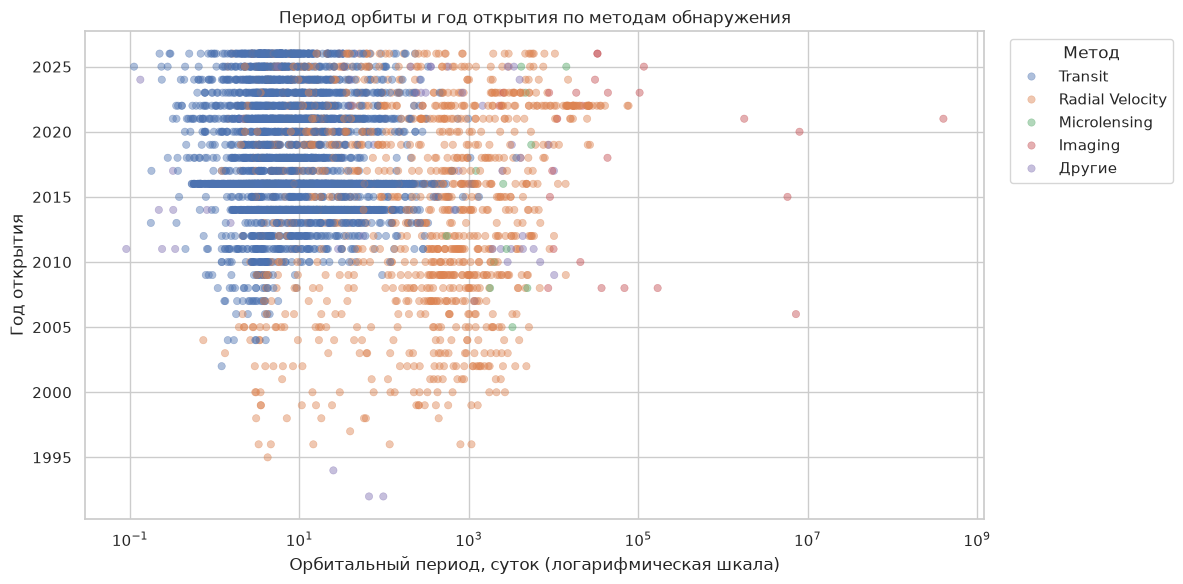

In [7]:
major_methods = ["Transit", "Radial Velocity", "Microlensing", "Imaging"]
plot_period = df_period.copy()
plot_period["method_group"] = plot_period["discovery_method"].where(
    plot_period["discovery_method"].isin(major_methods), "Другие"
)
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=plot_period, x="orbital_period_days", y="discovery_year",
    hue="method_group", hue_order=major_methods + ["Другие"],
    alpha=0.45, s=28, edgecolor=None,
)
plt.xscale("log")
plt.title("Период орбиты и год открытия по методам обнаружения")
plt.xlabel("Орбитальный период, суток (логарифмическая шкала)")
plt.ylabel("Год открытия")
plt.legend(title="Метод", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Интерпретация:** График наглядно демонстрирует эффект селекции. Транзитный метод (синие точки) плотно сконцентрирован в левой части графика (периоды < 100 суток). Это логично: чтобы зафиксировать транзит, планета должна часто проходить по диску звезды. Метод лучевых скоростей (оранжевые точки) «видит» более далекие планеты с периодами в сотни и тысячи суток, так как для них не требуется ждать прохождения по диску.

## 5. Сравнение методов обнаружения

Методов очень разное число, а распределения асимметричны. Поэтому рядом со средним радиусом приводим **медиану и размер выборки**. Среднее чувствительно к редким очень большим планетам; вывод по H1 будем делать по медиане.

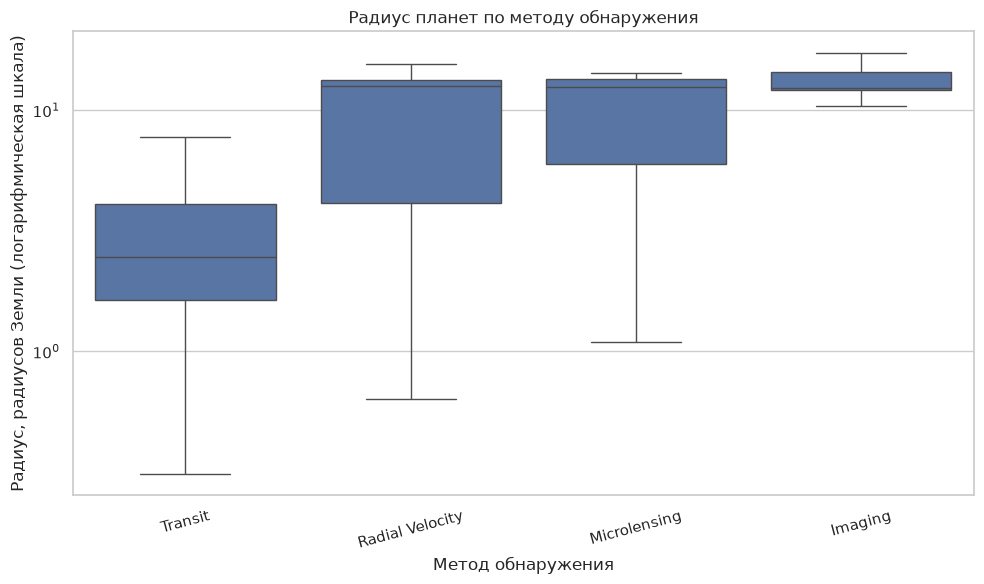

,planets,radius_count,mean_radius,median_radius,median_period_days
discovery_method,,,,,
Transit,4785,4784,4.38,2.46,7.97
Radial Velocity,1204,1167,9.79,12.60,306.69
Microlensing,292,292,10.06,12.50,3042.50
Imaging,98,94,15.56,12.42,33100.00
Transit Timing Variations,29,28,8.07,9.70,41.29
Eclipse Timing Variations,17,15,12.89,12.90,3160.00
Orbital Brightness Modulation,9,6,9.65,13.40,0.81
Pulsar Timing,8,6,5.41,1.86,25.26
Astrometry,6,6,12.45,12.25,334.76


In [8]:
plot_radius = df_radius[df_radius["discovery_method"].isin(major_methods)]
plt.figure(figsize=(10, 6))
sns.boxplot(data=plot_radius, x="discovery_method", y="radius_earth", order=major_methods, showfliers=False)
plt.yscale("log")
plt.title("Радиус планет по методу обнаружения")
plt.xlabel("Метод обнаружения")
plt.ylabel("Радиус, радиусов Земли (логарифмическая шкала)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

method_summary = (
    df.groupby("discovery_method")
      .agg(planets=("planet_name", "size"),
           radius_count=("radius_earth", "count"),
           mean_radius=("radius_earth", "mean"),
           median_radius=("radius_earth", "median"),
           median_period_days=("orbital_period_days", "median"))
      .sort_values("planets", ascending=False)
)
display(method_summary.round(2))

**Промежуточный вывод.** Сравнение медиан подтверждает разницу: у Transit медианный радиус равен 2,46 радиуса Земли, а у Radial Velocity — 12,6. Медиана здесь надежнее среднего значения, так как она менее чувствительна к редким гигантам. При этом выборки несопоставимы по размеру (4 785 против 1 204 планет). Это еще раз подчеркивает, что мы сравниваем не реальное соотношение планет, а то, как разные инструменты «фильтруют» объекты.

## 6. Многомерные связи

**Интерпретация методов:** Распределения массы и орбитального периода имеют ярко выраженную правостороннюю асимметрию (длинные хвосты). Если использовать их в исходном виде, редкие экстремально большие значения исказят коэффициент корреляции Пирсона. Поэтому для матрицы мы берем десятичные логарифмы этих признаков.

**Примечание:** `relative_density` математически выводится из массы и радиуса, поэтому его корреляция с ними — это математический трюизм, а не научное открытие.

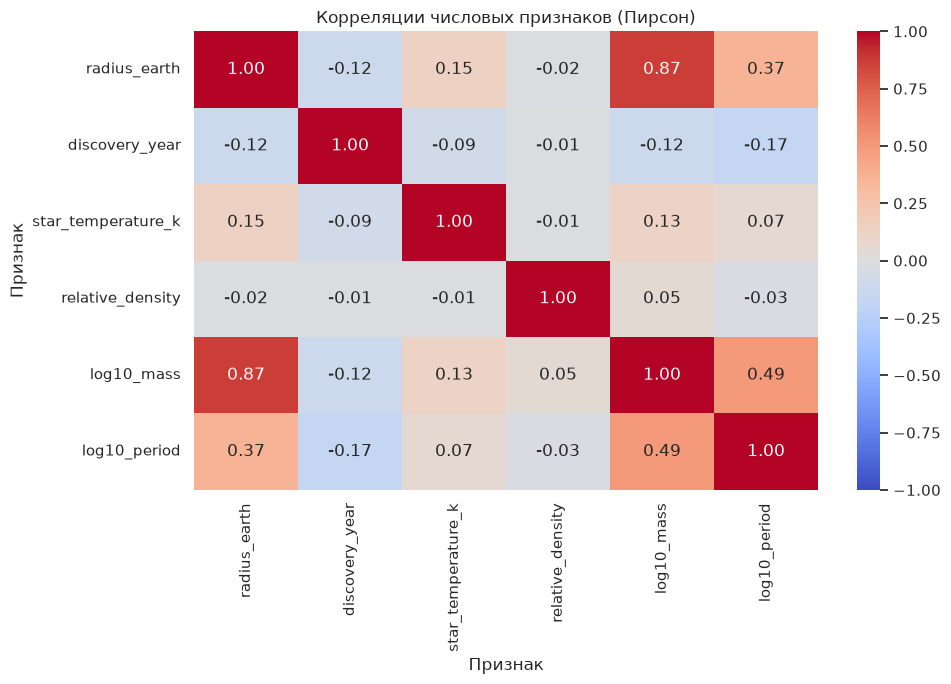

In [9]:
numeric = df[["radius_earth", "mass_earth", "orbital_period_days", "discovery_year", "star_temperature_k", "relative_density"]].copy()
numeric["log10_mass"] = np.log10(numeric["mass_earth"])
numeric["log10_period"] = np.log10(numeric["orbital_period_days"])
numeric = numeric.drop(columns=["mass_earth", "orbital_period_days"])
correlation = numeric.corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Корреляции числовых признаков (Пирсон)")
plt.xlabel("Признак")
plt.ylabel("Признак")
plt.tight_layout()
plt.show()

### Численная проверка гипотез

Для H1 и H2 сравниваем медианы только среди записей, где измерен соответствующий признак. Для H3 используем Спирмена: он оценивает монотонную связь и менее чувствителен к выбросам, чем корреляция Пирсона.

In [10]:
transit = df[df["discovery_method"] == "Transit"]
rv = df[df["discovery_method"] == "Radial Velocity"]
print(f"H1 — медианный радиус: Transit {transit['radius_earth'].median():.2f}; Radial Velocity {rv['radius_earth'].median():.2f} R⊕")
print(f"H2 — медианный период: Transit {transit['orbital_period_days'].median():.2f}; Radial Velocity {rv['orbital_period_days'].median():.2f} суток")
valid_temp = df[["radius_earth", "star_temperature_k"]].dropna()
rho = valid_temp.corr(method="spearman").loc["radius_earth", "star_temperature_k"]
print(f"H3 — Спирмен (радиус и температура звезды): {rho:.3f}; n = {len(valid_temp):,}")

peak_year = int(df["discovery_year"].value_counts().idxmax())
peak = df[df["discovery_year"] == peak_year]
print(f"Пиковый год: {peak_year}, открытий: {len(peak):,}")
display(peak["discovery_facility"].value_counts().head(5).rename_axis("Обсерватория / миссия").to_frame("Открытий"))

H1 — медианный радиус: Transit 2.46; Radial Velocity 12.60 R⊕
H2 — медианный период: Transit 7.97; Radial Velocity 306.69 суток
H3 — Спирмен (радиус и температура звезды): 0.196; n = 6,095
Пиковый год: 2016, открытий: 1,504


,Открытий
Обсерватория / миссия,
Kepler,1276
K2,103
Multiple Observatories,20
HATSouth,16
SuperWASP,12


## Выводы

1. Результаты проведенного анализа подтверждают выдвинутые гипотезы о различии выборок, формируемых разными методами обнаружения. Медианный радиус планет, открытых транзитным методом, составляет 2,46 радиуса Земли, тогда как для метода лучевых скоростей этот показатель равен 12,6. Аналогичная закономерность наблюдается и в распределении орбитальных периодов: медиана для транзитов составляет около 8 суток, а для лучевых скоростей — 307 суток. Данное расхождение объясняется спецификой физических ограничений инструментов: короткопериодические планеты совершают большее число транзитов за время наблюдений, а массивные планеты вызывают более заметные гравитационные колебания звезды. Следовательно, полученные распределения отражают эффект наблюдательной селекции, а не истинную популяцию экзопланет в Галактике.

2. Третья гипотеза, предполагавшая наличие связи между радиусом планеты и температурой родительской звезды, не получила убедительного подтверждения. Значение коэффициента корреляции Спирмена составило 0,196, что указывает на наличие лишь слабой положительной тенденции. Полученный результат демонстрирует, что температура звезды не является значимым предиктором размера планеты, и для построения прогностических моделей требуется учет более сложных физических параметров системы.

3. В целом, в рассматриваемом каталоге преобладают планеты радиусом от 2 до 4 радиусов Земли. Максимальное количество регистраций открытий приходится на 2016 год (1504 планеты), причем для 1276 из них в качестве источника указана миссия «Кеплер». Это подтверждает значительный вклад данной миссии в общую статистику, однако не позволяет утверждать, что она являлась единственной причиной наблюдаемого пика. Для повышения достоверности выводов и перехода от анализа наблюдаемой выборки к оценке генеральной совокупности необходимо расширить набор данных. В частности, требуется добавить информацию о неопределенностях масс и радиусов, флаги верхних границ, параметры родительских звезд, а также характеристики наблюдательных программ. Учет оценок полноты обнаружения позволит применять веса к наблюдениям, что даст возможность корректировать эффекты отбора и отделять истинные физические свойства планет от ограничений методов их поиска.